In [1]:
import numpy as np
import matplotlib.pyplot as plt

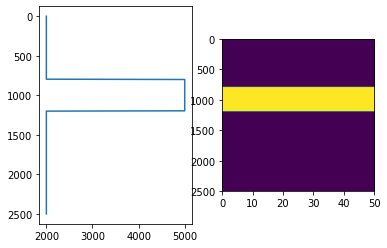

In [9]:
def plot_log(axis, val, n_copies=10, aspect=50):
    fig,ax = plt.subplots(1, 2)
    ax[0].plot(val, axis)
    ax[0].invert_yaxis()
    ax[1].imshow(np.tile(val, (n_copies,1)).T, extent=[0, aspect, axis.max(), axis.min()])
    ax[1].set_aspect(1/aspect)

one_way_time = np.linspace(0, 2500, 626)
vel = np.zeros_like(one_way_time)
vel[0:200] = 2000.
vel[200:300] = 5000.
vel[300:] = 2000.
plot_log(one_way_time, vel)

In [20]:
reflectivity_up = (vel - np.roll(vel,1)) / (vel + np.roll(vel,1))
reflectivity_up[0] = 0.

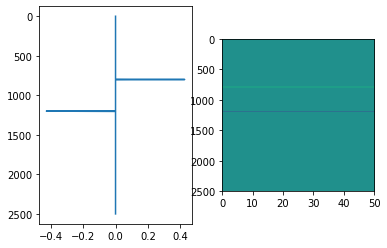

In [21]:
plot_log(one_way_time, reflectivity_up)

In [22]:
transmission_down = np.sqrt(1. - reflectivity_up ** 2.)

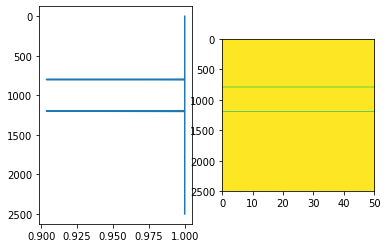

In [23]:
plot_log(one_way_time, transmission_down)

In [28]:
reflectivity_down = -reflectivity_up
reflectivity_down[0] = 1.
transmission_up = np.sqrt(1. - reflectivity_down ** 2.)

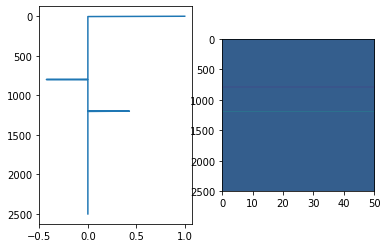

In [29]:
plot_log(one_way_time, reflectivity_down)

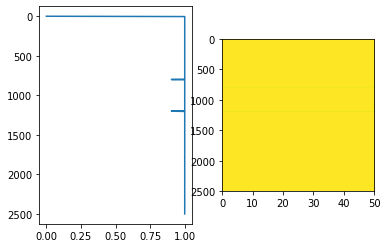

In [30]:
plot_log(one_way_time, transmission_up)

In [50]:
def ray_tracing_full(reflectivity_up, reflectivity_down, transmission_up, transmission_down):
    wf = np.zeros([reflectivity_up.shape[0], reflectivity_up.shape[0]*2, 2])
    wf[0,0,0] = 1. #initial condition
    for t in range(1, wf.shape[1]):
        for i in range(0, wf.shape[0]):
            T = np.array([transmission_down[i], reflectivity_down[i], reflectivity_up[i], transmission_up[i]]).reshape(2,2)
            if i == 0:
                wf[i,t] = T @ np.array([0, wf[i+1, t-1, 1]])
            elif i == wf.shape[0]-1:
                wf[i,t] = T @ np.array([wf[i-1, t-1, 0], 0])
            else:
                wf[i,t] = T @ np.array([wf[i-1, t-1, 0], wf[i+1, t-1, 1]])
    return wf

In [51]:
wf = ray_tracing_full(reflectivity_up, reflectivity_down, transmission_up, transmission_down)

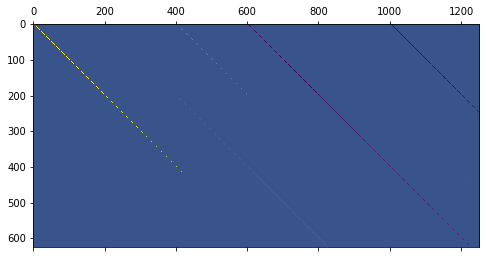

In [58]:
plt.matshow(wf[:,:,0])

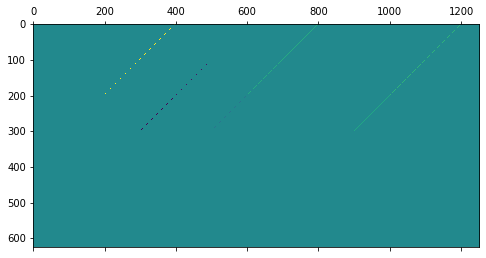

In [59]:
plt.matshow(wf[:,:,1])

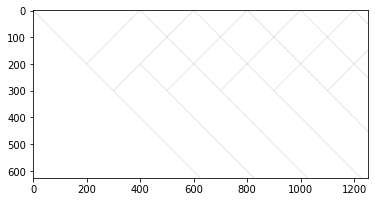

In [96]:
plt.imshow(np.abs(wf[:,:,0] + wf[:,:,1])>0, cmap='Greys')

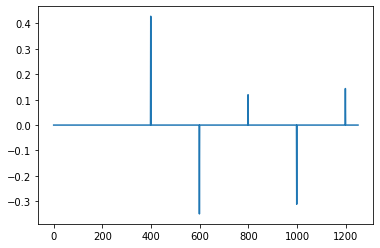

In [73]:
plt.plot(wf[1,:,1])

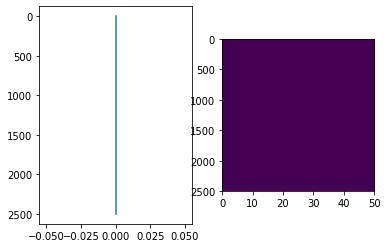

In [76]:
reflectivity_down_primary = np.zeros_like(reflectivity_down)
#reflectivity_down_primary[0] = 1.
plot_log(one_way_time, reflectivity_down_primary)

In [77]:
wf_primary = ray_tracing_full(reflectivity_up, reflectivity_down_primary, transmission_up, transmission_down)

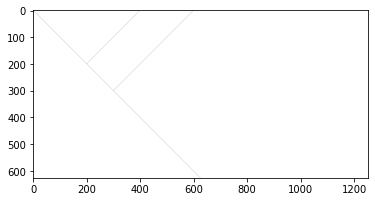

In [95]:
plt.imshow(np.abs(wf_primary[:,:,0] + wf_primary[:,:,1])>0, cmap='Greys')

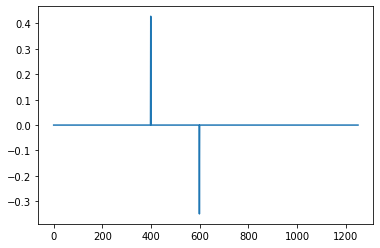

In [79]:
plt.plot(wf_primary[1,:,1])

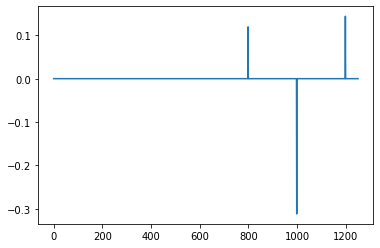

In [81]:
plt.plot(wf[1,:,1] - wf_primary[1,:,1])

In [82]:
reflectivity_down_ns = reflectivity_down
reflectivity_down_ns[0] = 0.

In [84]:
wf_ns = ray_tracing_full(reflectivity_up, reflectivity_down_ns, transmission_up, transmission_down)

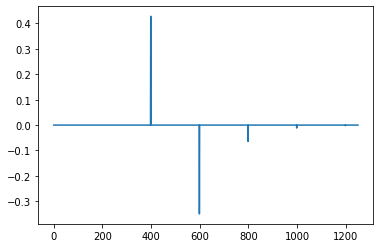

In [85]:
plt.plot(wf_ns[1,:,1])

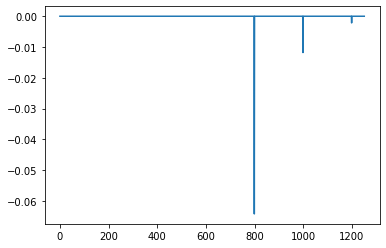

In [86]:
plt.plot(wf_ns[1,:,1]- wf_primary[1,:,1])

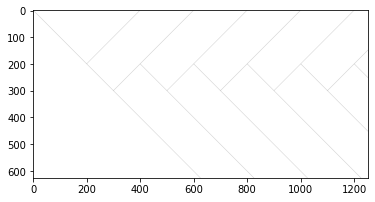

In [97]:
plt.imshow(np.abs(wf_ns[:,:,0] + wf_ns[:,:,1])>0, cmap='Greys')